In [236]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

In [237]:
filepath = '/content/drive/MyDrive/Ict_files/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(filepath)

##EDA

In [238]:
df.shape

(7043, 21)

In [239]:
df.size

147903

In [240]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [241]:
df.sample()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
1260,9992-UJOEL,Male,0,No,No,2,Yes,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,50.3,92.75,No


In [242]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [243]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [244]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [245]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [246]:
df.index

RangeIndex(start=0, stop=7043, step=1)

In [247]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [248]:
df.memory_usage()

,0
Index,132
customerID,56344
gender,56344
SeniorCitizen,56344
Partner,56344
Dependents,56344
tenure,56344
PhoneService,56344
MultipleLines,56344
InternetService,56344


In [249]:
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [250]:
df.duplicated().sum()

np.int64(0)

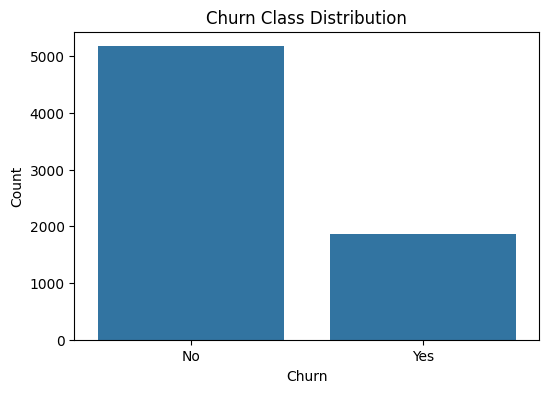

In [251]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn')
plt.title('Churn Class Distribution')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.show()

In [252]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


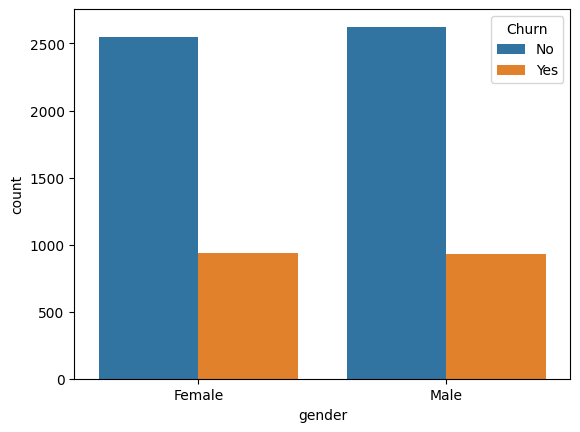

In [253]:
sns.countplot(data=df, x='gender', hue='Churn')
plt.show()

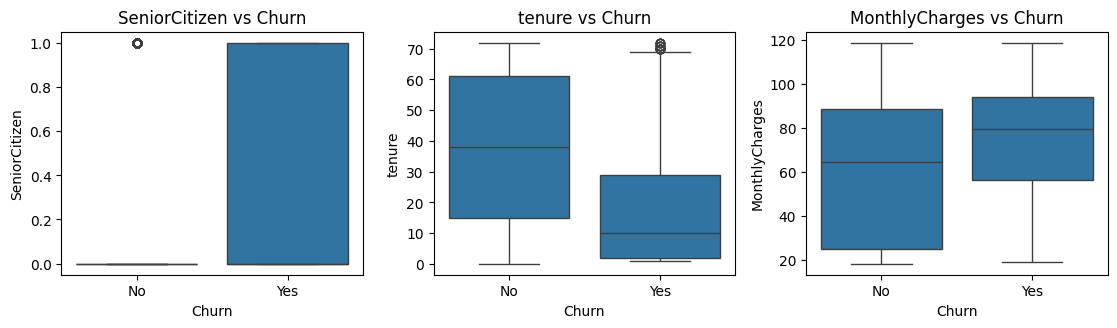

In [254]:
num_cols = df.select_dtypes(include='number').columns

plt.figure(figsize=(15, 12))

for i, col in enumerate(num_cols, 1):
    plt.subplot(4, 4, i)

    sns.boxplot(data=df, x='Churn', y=col)

    plt.title(f'{col} vs Churn')
    plt.xlabel('Churn')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

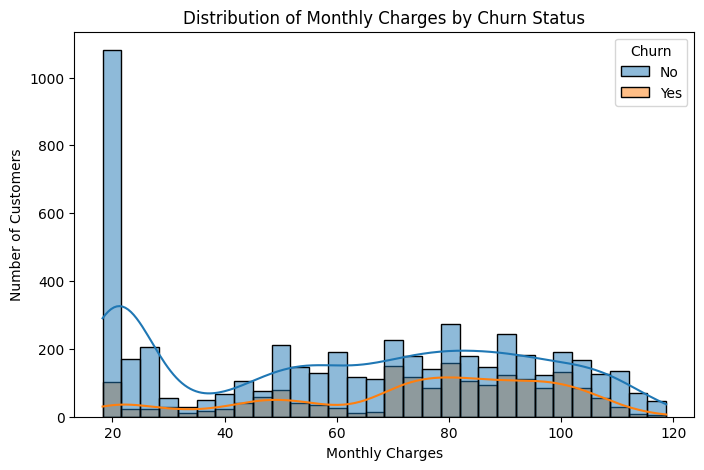

In [255]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x='MonthlyCharges', hue='Churn', bins=30, kde=True)

plt.title('Distribution of Monthly Charges by Churn Status')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')

plt.show()

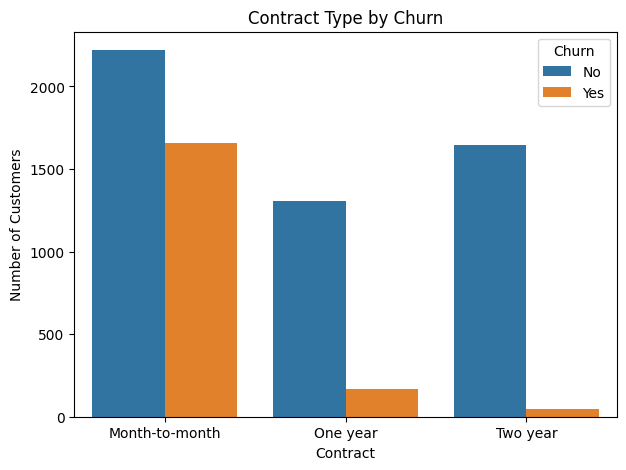

In [256]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Contract Type by Churn')
plt.xlabel('Contract')
plt.ylabel('Number of Customers')
plt.show()

##Data Cleaning

In [257]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


##Checking missing values

In [258]:
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [259]:
(df.isna().sum()/len(df))*100

,0
customerID,0.000000
gender,0.000000
SeniorCitizen,0.000000
Partner,0.000000
Dependents,0.000000
tenure,0.000000
PhoneService,0.000000
MultipleLines,0.000000
InternetService,0.000000
OnlineSecurity,0.000000


In [260]:
df.dropna(subset='TotalCharges', inplace = True)

In [261]:
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


##Duplicate values handling

In [262]:
df = df.drop(columns='customerID')

In [263]:
df.duplicated().sum()

np.int64(22)

In [264]:
df = df.drop_duplicates()
print(df.duplicated().sum())
df.shape

0


(7010, 20)

##Outlier Handling

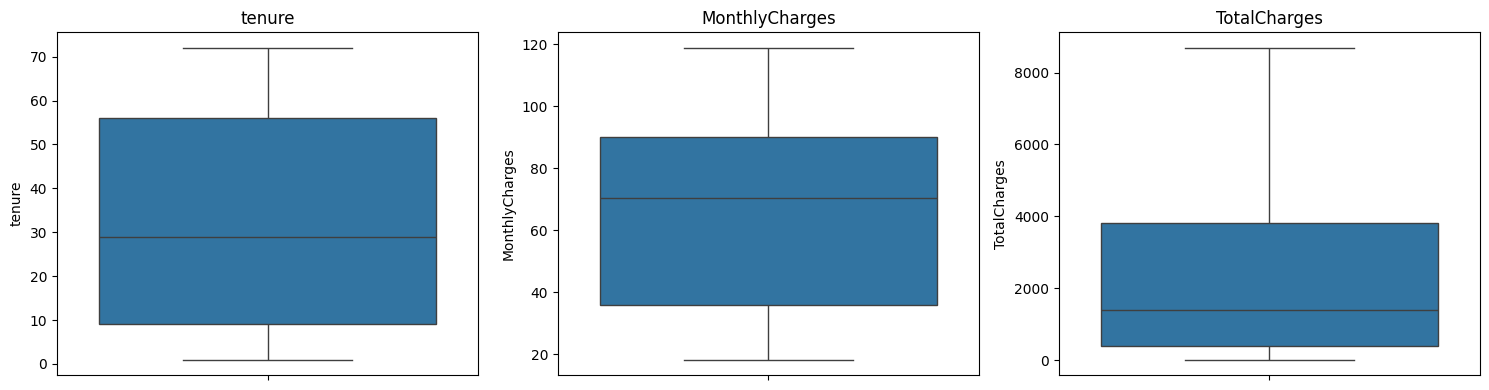

In [265]:
out_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

plt.figure(figsize=(15, 4))
for i, col in enumerate(out_cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(data=df, y=col)
    plt.title(col)
plt.tight_layout()
plt.show()

In [266]:
for col in out_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum()
    print(f"{col}: {n_out} outliers")

tenure: 0 outliers
MonthlyCharges: 0 outliers
TotalCharges: 0 outliers


##Feature Target seperation

In [267]:
y = df['Churn']
X = df.drop('Churn', axis=1)

In [268]:
y.value_counts()

,count
Churn,
No,5153
Yes,1857


In [269]:
(y.value_counts()/len(y))*100

,count
Churn,
No,73.509272
Yes,26.490728


##Train_Test split


In [270]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [271]:
print("Train :", X_train.shape)
print("Test  :", X_test.shape)

Train : (5608, 19)
Test  : (1402, 19)


##Num and cat columns

In [272]:
cat_cols = X_train.select_dtypes(exclude='number').columns

num_cols = X_train.select_dtypes(include='number').columns

print(list(num_cols))
print(list(cat_cols))
print()
for col in cat_cols:
  print(f"{col}===>{df[col].unique()}")

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

gender===>['Female' 'Male']
Partner===>['Yes' 'No']
Dependents===>['No' 'Yes']
PhoneService===>['No' 'Yes']
MultipleLines===>['No phone service' 'No' 'Yes']
InternetService===>['DSL' 'Fiber optic' 'No']
OnlineSecurity===>['No' 'Yes' 'No internet service']
OnlineBackup===>['Yes' 'No' 'No internet service']
DeviceProtection===>['No' 'Yes' 'No internet service']
TechSupport===>['No' 'Yes' 'No internet service']
StreamingTV===>['No' 'Yes' 'No internet service']
StreamingMovies===>['No' 'Yes' 'No internet service']
Contract===>['Month-to-month' 'One year' 'Two year']
PaperlessBilling===>['Yes' 'No']
PaymentMethod===>['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (

Imputing

In [273]:
imputer_num = SimpleImputer(strategy='median')
X_train_num = imputer_num.fit_transform(X_train[num_cols])
X_test_num = imputer_num.transform(X_test[num_cols])

imputer_cat = SimpleImputer(strategy='most_frequent')
X_train_cat = pd.DataFrame(imputer_cat.fit_transform(X_train[cat_cols]), columns=cat_cols, index=X_train.index)
X_test_cat = pd.DataFrame(imputer_cat.transform(X_test[cat_cols]), columns=cat_cols, index=X_test.index)

##Scaling

In [274]:
scaler = StandardScaler()
X_train_num_scaled = scaler.fit_transform(X_train_num)
X_test_num_scaled = scaler.transform(X_test_num)

X_train_num_scaled = pd.DataFrame(X_train_num_scaled, columns=num_cols, index=X_train.index)
X_test_num_scaled = pd.DataFrame(X_test_num_scaled, columns=num_cols, index=X_test.index)

##Encoding

In [275]:
for col in cat_cols:
  print(f"{col}===>{X_train[col].unique()}")

gender===>['Female' 'Male']
Partner===>['No' 'Yes']
Dependents===>['No' 'Yes']
PhoneService===>['Yes' 'No']
MultipleLines===>['Yes' 'No phone service' 'No']
InternetService===>['DSL' 'Fiber optic' 'No']
OnlineSecurity===>['Yes' 'No' 'No internet service']
OnlineBackup===>['No' 'Yes' 'No internet service']
DeviceProtection===>['No' 'Yes' 'No internet service']
TechSupport===>['No' 'Yes' 'No internet service']
StreamingTV===>['No' 'Yes' 'No internet service']
StreamingMovies===>['No' 'Yes' 'No internet service']
Contract===>['Month-to-month' 'Two year' 'One year']
PaperlessBilling===>['Yes' 'No']
PaymentMethod===>['Electronic check' 'Bank transfer (automatic)' 'Mailed check'
 'Credit card (automatic)']


In [276]:
ordinal_encoder = OrdinalEncoder(categories=[['Month-to-month', 'One year', 'Two year']],
                                 handle_unknown='use_encoded_value', unknown_value=-1)

X_train_ord = pd.DataFrame(ordinal_encoder.fit_transform(X_train_cat[['Contract']]), columns=['Contract'], index=X_train.index)
X_test_ord = pd.DataFrame(ordinal_encoder.transform(X_test_cat[['Contract']]), columns=['Contract'], index=X_test.index)

In [277]:
one_hot_cols = [col for col in cat_cols if col != 'Contract']

one_hot_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_train_one_hot = one_hot_encoder.fit_transform(X_train_cat[one_hot_cols])
X_test_one_hot = one_hot_encoder.transform(X_test_cat[one_hot_cols])

col_names = one_hot_encoder.get_feature_names_out(one_hot_cols)

X_train_one_hot = pd.DataFrame(X_train_one_hot, columns=col_names, index=X_train.index)
X_test_one_hot = pd.DataFrame(X_test_one_hot, columns=col_names, index=X_test.index)

##Combining numerical and categorical features

In [278]:
X_train_final = pd.concat([X_train_num_scaled, X_train_ord, X_train_one_hot], axis=1)
X_test_final = pd.concat([X_test_num_scaled, X_test_ord, X_test_one_hot], axis=1)

print(X_train_final.shape, X_test_final.shape)

(5608, 43) (1402, 43)


##Label Encoding

In [279]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print(label_encoder.classes_)
print(pd.Series(y_train_encoded).value_counts().to_dict())

['No' 'Yes']
{0: 4122, 1: 1486}


##Handling class imbalance

In [280]:
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_final, y_train_encoded)

print("Before SMOTE:", pd.Series(y_train_encoded).value_counts().to_dict())
print("After SMOTE:", pd.Series(y_train_resampled).value_counts().to_dict())
print(X_train_final.shape, "->", X_train_resampled.shape)

Before SMOTE: {0: 4122, 1: 1486}
After SMOTE: {0: 4122, 1: 4122}
(5608, 43) -> (8244, 43)


##Correlation and feature selection

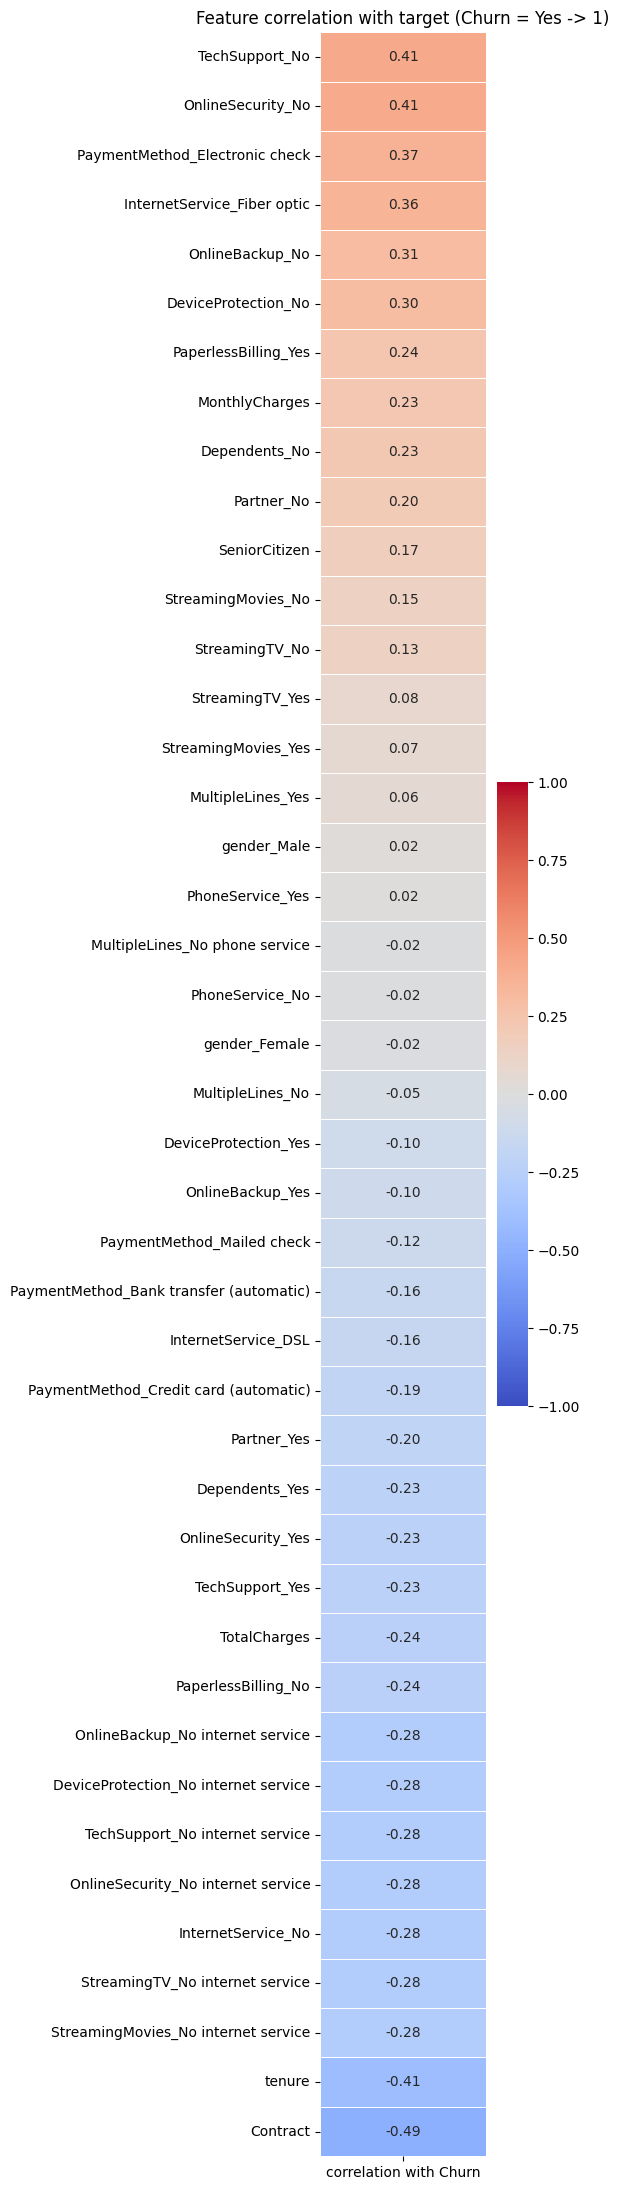

In [281]:
y_series = pd.Series(y_train_resampled, index=X_train_resampled.index)

corr_target = (
    X_train_resampled.corrwith(y_series)
    .sort_values(ascending=False)
    .to_frame(name="correlation with Churn")
)

plt.figure(figsize=(6, 22))
sns.heatmap(
    corr_target,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Feature correlation with target (Churn = Yes -> 1)")
plt.tight_layout()
plt.show()

In [282]:
selected_features = [
    'Contract',
    'tenure',
    'OnlineSecurity_No',
    'TechSupport_No',
    'PaymentMethod_Electronic check',
    'InternetService_Fiber optic',
    'OnlineBackup_No',
    'DeviceProtection_No',
    'InternetService_No',
    'MonthlyCharges'
]

X_train_selected = X_train_resampled[selected_features]
X_test_selected = X_test_final[selected_features]

print(X_train_selected.shape, X_test_selected.shape)

(8244, 10) (1402, 10)


##Model Building

In [283]:
X_train_model, X_val, y_train_model, y_val = train_test_split(
    X_train_selected,
    y_train_resampled,
    test_size=0.2,
    random_state=42,
    stratify=y_train_resampled
)

In [284]:
k_values = [3, 5, 7, 9, 11, 13, 15, 17, 19, 21]
k_f1_scores = []

for k in k_values:

    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_model, y_train_model)

    knn_val_pred = knn.predict(X_val)

    val_f1 = f1_score(y_val, knn_val_pred)

    k_f1_scores.append(val_f1)

    print("K =", k, "F1 Score =", val_f1)

best_k = k_values[k_f1_scores.index(max(k_f1_scores))]

print("Best K:", best_k)

K = 3 F1 Score = 0.8033775633293124
K = 5 F1 Score = 0.8038163387000596
K = 7 F1 Score = 0.8158508158508159
K = 9 F1 Score = 0.8107163657542225
K = 11 F1 Score = 0.8069767441860465
K = 13 F1 Score = 0.814985590778098
K = 15 F1 Score = 0.817762399077278
K = 17 F1 Score = 0.8125
K = 19 F1 Score = 0.810126582278481
K = 21 F1 Score = 0.8128219805380652
Best K: 15


In [285]:
log_reg = LogisticRegression()
knn = KNeighborsClassifier(n_neighbors=best_k)

In [286]:
# Fit the models
log_reg.fit(X_train_model, y_train_model)
knn.fit(X_train_model, y_train_model)

KNeighborsClassifier(n_neighbors=15)

In [287]:
# predicting using Logistic Regression model
lr_train_pred = log_reg.predict(X_train_model)
lr_test_pred = log_reg.predict(X_test_selected)

In [288]:
# predicting using KNN model
knn_train_pred = knn.predict(X_train_model)
knn_test_pred = knn.predict(X_test_selected)

In [289]:
lr_train_acc = accuracy_score(y_train_model, lr_train_pred)

lr_test_acc = accuracy_score(y_test_encoded, lr_test_pred)

In [290]:
knn_train_acc = accuracy_score(y_train_model, knn_train_pred)

knn_test_acc = accuracy_score(y_test_encoded, knn_test_pred)

In [291]:
print("Logistic Regression Training Accuracy:", lr_train_acc)
print("Logistic Regression Testing Accuracy:", lr_test_acc)

print("KNN Training Accuracy:", knn_train_acc)
print("KNN Testing Accuracy:", knn_test_acc)

Logistic Regression Training Accuracy: 0.7649734647460197
Logistic Regression Testing Accuracy: 0.7532097004279601
KNN Training Accuracy: 0.8159211523881729
KNN Testing Accuracy: 0.7253922967189729


In [292]:
lr_cm = confusion_matrix(y_test_encoded, lr_test_pred)

print("Confusion matrix of Logistic Regression")
print(lr_cm)

Confusion matrix of Logistic Regression
[[772 259]
 [ 87 284]]


In [293]:
knn_cm = confusion_matrix(y_test_encoded, knn_test_pred)

print("Confusion matrix of KNN")
print(knn_cm)

Confusion matrix of KNN
[[743 288]
 [ 97 274]]


In [294]:
lr_cr = classification_report(y_test_encoded, lr_test_pred)

print("Classification report of Logistic Regression")
print(lr_cr)

Classification report of Logistic Regression
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1031
           1       0.52      0.77      0.62       371

    accuracy                           0.75      1402
   macro avg       0.71      0.76      0.72      1402
weighted avg       0.80      0.75      0.77      1402



In [295]:
knn_cr = classification_report(y_test_encoded, knn_test_pred)

print("Classification report of KNN")
print(knn_cr)

Classification report of KNN
              precision    recall  f1-score   support

           0       0.88      0.72      0.79      1031
           1       0.49      0.74      0.59       371

    accuracy                           0.73      1402
   macro avg       0.69      0.73      0.69      1402
weighted avg       0.78      0.73      0.74      1402



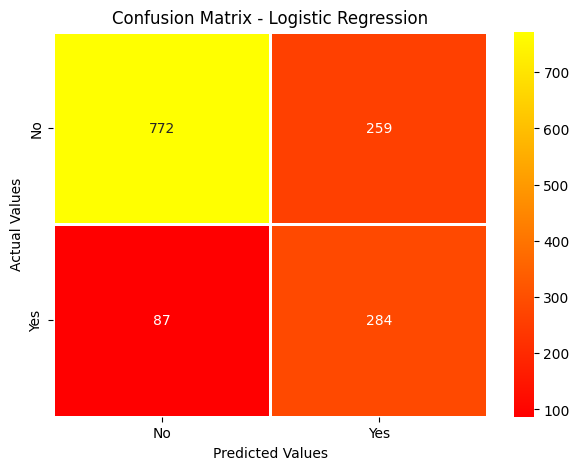

In [296]:
plt.figure(figsize=(7,5))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt='d',
    cmap='autumn',
    linewidths=1,
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

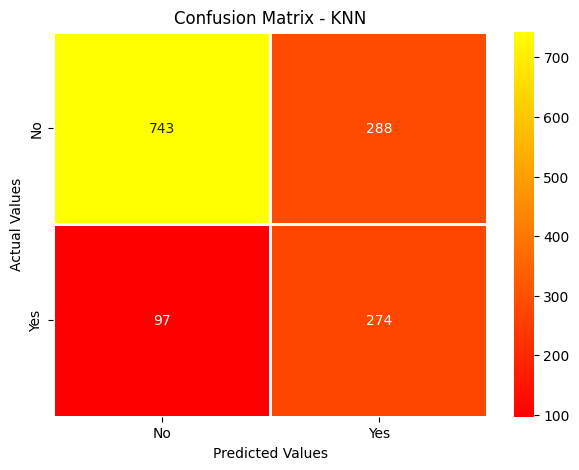

In [297]:
plt.figure(figsize=(7,5))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt='d',
    cmap='autumn',
    linewidths=1,
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title('Confusion Matrix - KNN')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [298]:
# Predicting probabilities using Logistic Regression
lr_test_prob = log_reg.predict_proba(X_test_selected)[:, 1]

In [299]:
thresholds = [0.3, 0.5, 0.7]

for threshold in thresholds:

    threshold_pred = (lr_test_prob >= threshold).astype(int)

    print("\nThreshold:", threshold)

    print("Accuracy:", accuracy_score(y_test_encoded, threshold_pred))
    print("Precision:", precision_score(y_test_encoded, threshold_pred))
    print("Recall:", recall_score(y_test_encoded, threshold_pred))
    print("F1-score:", f1_score(y_test_encoded, threshold_pred))


Threshold: 0.3
Accuracy: 0.6690442225392297
Precision: 0.4409148665819568
Recall: 0.9353099730458221
F1-score: 0.5993091537132987

Threshold: 0.5
Accuracy: 0.7532097004279601
Precision: 0.5230202578268877
Recall: 0.7654986522911051
F1-score: 0.6214442013129103

Threshold: 0.7
Accuracy: 0.8002853067047075
Precision: 0.6342182890855457
Recall: 0.5795148247978437
F1-score: 0.6056338028169014


##Model comparison

In [301]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Logistic Regression
lr_precision = precision_score(y_test_encoded, lr_test_pred)
lr_recall = recall_score(y_test_encoded, lr_test_pred)
lr_f1 = f1_score(y_test_encoded, lr_test_pred)

# KNN
knn_precision = precision_score(y_test_encoded, knn_test_pred)
knn_recall = recall_score(y_test_encoded, knn_test_pred)
knn_f1 = f1_score(y_test_encoded, knn_test_pred)

In [302]:
print("Logistic Regression Performance")
print("Accuracy:", lr_test_acc)
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1-score:", lr_f1)

print("\nKNN Performance")
print("Accuracy:", knn_test_acc)
print("Precision:", knn_precision)
print("Recall:", knn_recall)
print("F1-score:", knn_f1)

Logistic Regression Performance
Accuracy: 0.7532097004279601
Precision: 0.5230202578268877
Recall: 0.7654986522911051
F1-score: 0.6214442013129103

KNN Performance
Accuracy: 0.7253922967189729
Precision: 0.4875444839857651
Recall: 0.738544474393531
F1-score: 0.587352625937835


After evaluating both Logistic Regression and KNN models,it can be observed that Logistic Regression performs better than KNN across all four evaluation metrics

In customer churn prediction, false negatives can be particularly costly because the company misses an opportunity to retain customers who are actually planning to leave